# Question 2 — Implementing CNN layers with NumPy
**IFT6135 · Programming · 20 points**

Implement 3×3 convolution and 2×2 max pooling, assemble the specified CNN,
and investigate recognition of a local tile pattern at new locations.
This notebook is independent of Question 1.

Complete four functions in `cnn_layers.py` and `build_model` in `cnn.py`,
then run the experiment and report your results. Supporting code is provided.
Use NumPy only.

Public tests are provided for debugging; additional private tests will be used for grading.

## 0. Setup
Run the notebook in order. All supporting files are embedded below; sharing a
notebook does not require sharing a preconfigured virtual machine.

Edit the TODOs in the two write-file cells. Rerunning
those cells replaces the corresponding `.py` files. Do not edit a second copy in
the file browser and then overwrite it by running an unchanged cell.
Only NumPy and Matplotlib are required; a CPU runtime is sufficient.

In [1]:
import os
from pathlib import Path
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
if Path.cwd().name != "q2_workspace":
    workspace = Path.cwd() / "q2_workspace"
    workspace.mkdir(exist_ok=True)
    os.chdir(workspace)
print("Working directory:", Path.cwd())
import numpy as np
import matplotlib.pyplot as plt
import json, importlib
print("NumPy:", np.__version__)

Working directory: /store/home/mardenlim/IFT6135/Assignments_IFT6135/Assignment1/q2/q2_workspace
NumPy: 1.26.4


## 1. CNN layer implementation

In this question, convolution uses **3×3 kernels, stride 1, and zero-padding 1**.
Local max pooling uses **2×2 windows, stride 2, and no padding**.
Convolution follows the cross-correlation convention (no filter flip).

| Function | Return |
|---|---|
| `conv2d_forward(x, weight, bias)` | `(out, cache)`, with `out` of shape `(N, Cout, H, W)` |
| `conv2d_backward(dout, cache)` | `(dx, dweight, dbias)` |
| `maxpool2d_forward(x)` | `(out, cache)`, with `out` of shape `(N, C, H//2, W//2)` |
| `maxpool2d_backward(dout, cache)` | `dx`, with the same shape as the input |

Inputs use **NCHW** ordering. Convolutional weights have shape
`(Cout, Cin, 3, 3)` and biases have shape `(Cout,)`.

For max-pooling ties, select the first maximum in row-major order
(top-left, top-right, bottom-left, bottom-right) and propagate the
gradient only to that position.

Use **NumPy only** for your implementation. NumPy padding, matrix
multiplication, window extraction, and loops are allowed. Do not use
SciPy, PyTorch, or another library's convolution, pooling, or automatic
differentiation operations.

Complete the four TODOs below. Additional input and return requirements
are specified in the function docstrings.

In [ ]:
%%writefile cnn_layers.py
"""Q2 implementations: NumPy only, no automatic differentiation.

All spatial tensors use NCHW. Implement only the four functions below.
The geometry is fixed: 3x3 cross-correlation, stride 1, zero padding 1;
2x2 max pooling, stride 2, no padding. Do not generalize the API.

Inputs are finite float32 or float64 arrays. Inputs belonging to a call have
matching dtypes. Preserve that dtype; never modify input arrays in place.
Support arbitrary positive batch/channel sizes and H,W >= 2. Pooling requires
even H,W. Noncontiguous NumPy views are valid inputs. A cache is an opaque,
per-forward object: choose its structure, but do not use global state.
A backward call returns fresh gradients, does not update parameters, and does
not divide by the batch size. The incoming gradient already incorporates any
loss reduction. Separate outstanding caches must work independently.
"""
from typing import Any
import numpy as np


def conv2d_forward(x: np.ndarray, weight: np.ndarray,
                   bias: np.ndarray) -> tuple[np.ndarray, Any]:
    """Apply 3x3 cross-correlation with stride 1 and zero padding 1.

    Parameters
    ----------
    x : ndarray, shape (N, C_in, H, W)
    weight : ndarray, shape (C_out, C_in, 3, 3)
        Do not flip the kernel. All channels contribute to each output filter.
    bias : ndarray, shape (C_out,)
        Add one scalar to every output position in the corresponding channel.

    Returns
    -------
    out : ndarray, shape (N, C_out, H, W)
        Same floating dtype as x.
    cache : object
        Information your conv2d_backward needs. Its structure is your choice.
        Do not update weights or biases in this function.
    """
    N, C_in, H, W = x.shape
    C_out = weight.shape[0]
    dtype = x.dtype
 
    # One pixel of zero padding on each spatial side
    xp = np.pad(x, ((0, 0), (0, 0), (1, 1), (1, 1)))
 
    # Cross-correlation as a sum over the 9 kernel offsets (i, j)
    out = np.zeros((N, C_out, H, W), dtype=dtype)
    for i in range(3):
        for j in range(3):
            patch = xp[:, :, i:i + H, j:j + W]  
            out += np.einsum('nchw,oc->nohw', patch, weight[:, :, i, j], optimize=True)
    out += bias.reshape(1, C_out, 1, 1)
 
    # Copy the weights 
    cache = (xp, weight.copy(), H, W)
    return out.astype(dtype, copy=False), cache


def conv2d_backward(dout: np.ndarray, cache: Any
                    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Backpropagate through the matching conv2d_forward call.

    Parameters
    ----------
    dout : ndarray, shape (N, C_out, H, W)
        Upstream derivative of a scalar loss with respect to the output.
    cache : object returned by your conv2d_forward

    Returns
    -------
    dx : ndarray, shape (N, C_in, H, W)
    dweight : ndarray, shape (C_out, C_in, 3, 3)
    dbias : ndarray, shape (C_out,)
        Sum contributions over the batch and spatial axes; do not average.
        Return (dx, dweight, dbias), in that order, in the input dtype.
        Overlapping receptive fields must accumulate their input gradients.
    """
    xp, weight, H, W = cache
    dtype = xp.dtype
    dbias = dout.sum(axis=(0, 2, 3))
    dweight = np.zeros_like(weight)
    dxp = np.zeros_like(xp)
    
    for i in range(3):
        for j in range(3):
            patch = xp[:, :, i:i + H, j:j + W]
            dweight[:, :, i, j] = np.einsum('nohw,nchw->oc', dout, patch, optimize=True)

            dxp[:, :, i:i + H, j:j + W] += np.einsum('nohw,oc->nchw', dout, weight[:, :, i, j], optimize=True)
 
    # Remove the padding border
    dx = dxp[:, :, 1:-1, 1:-1].copy()
    return dx.astype(dtype, copy=False), dweight.astype(dtype, copy=False), dbias.astype(dtype, copy=False)


def maxpool2d_forward(x: np.ndarray) -> tuple[np.ndarray, Any]:
    """Apply 2x2 max pooling with stride 2 and no padding.

    Parameters
    ----------
    x : ndarray, shape (N, C, H, W)
        H and W must be even. Values may be negative or repeated.

    Returns
    -------
    out : ndarray, shape (N, C, H//2, W//2), same dtype as x
    cache : object
        Information your maxpool2d_backward needs. At tied maxima, select
        only the first maximum in row-major order within the 2x2 window:
        top-left, top-right, bottom-left, bottom-right. Cache this selection.
    """
    N, C, H, W = x.shape
    if H % 2 or W % 2:
        raise ValueError('maxpool2d_forward requires even H and W')
    H2, W2 = H // 2, W // 2
 
    # Split each spatial axis into (block, offset)
    windows = (x.reshape(N, C, H2, 2, W2, 2)
                .transpose(0, 1, 2, 4, 3, 5)
                .reshape(N, C, H2, W2, 4))
 
    index = np.argmax(windows, axis=-1)   
    out = np.take_along_axis(windows, index[..., None], axis=-1)[..., 0]
 
    cache = (index, x.shape, x.dtype)
    return out.astype(x.dtype, copy=False), cache


def maxpool2d_backward(dout: np.ndarray, cache: Any) -> np.ndarray:
    """Route each upstream gradient to its selected maximum.

    Parameters
    ----------
    dout : ndarray, shape (N, C, H//2, W//2)
    cache : object returned by your maxpool2d_forward

    Returns
    -------
    dx : ndarray, shape (N, C, H, W), same dtype as the forward input
        One selected position receives the upstream gradient per window;
        all other positions receive zero. Do not split a tied gradient or
        send it to every tied maximum. Do not average or update any arrays.
    """
    index, shape, dtype = cache
    N, C, H, W = shape
    H2, W2 = H // 2, W // 2
 
    dwindows = np.zeros((N, C, H2, W2, 4), dtype=dtype)
    np.put_along_axis(dwindows, index[..., None], dout[..., None].astype(dtype), axis=-1)
 
    # Undo the window reshape from the forward pass
    dx = (dwindows.reshape(N, C, H2, W2, 2, 2)
                  .transpose(0, 1, 2, 4, 3, 5)
                  .reshape(N, C, H, W))
    return dx

Writing cnn_layers.py


## 2. Provided support and public tests
Run these cells without modifying them. They provide the independent Q2 training
code, dataset generator and public tests. The source remains available for inspection.

In [3]:
%%writefile support.py
"""Provided Q2 support code. No changes and no Q1 imports.

The only dependencies are NumPy, the cnn_layers module, and the
Python standard library. All training and differentiation run in NumPy.
"""
from __future__ import annotations
from copy import deepcopy
from pathlib import Path
import json
import time
import numpy as np
import cnn_layers


class Conv2D:
    """Fixed 3x3, stride-1, pad-1 wrapper; He-normal weights, zero bias."""
    def __init__(self, in_channels: int, out_channels: int,
                 rng: np.random.Generator):
        self.weight = (rng.standard_normal((out_channels, in_channels, 3, 3))
                       * np.sqrt(2.0 / (in_channels * 9))).astype(np.float32)
        self.bias = np.zeros(out_channels, dtype=np.float32)
        self.dweight = np.zeros_like(self.weight)
        self.dbias = np.zeros_like(self.bias)

    def forward(self, x):
        out, self.cache = cnn_layers.conv2d_forward(x, self.weight, self.bias)
        return out

    def backward(self, dout):
        dx, self.dweight, self.dbias = cnn_layers.conv2d_backward(dout, self.cache)
        return dx


class MaxPool2D:
    def forward(self, x):
        out, self.cache = cnn_layers.maxpool2d_forward(x)
        return out

    def backward(self, dout):
        return cnn_layers.maxpool2d_backward(dout, self.cache)


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return np.maximum(x, 0)

    def backward(self, dout):
        return dout * self.mask


class GlobalMaxPool2D:
    """Spatial maximum per channel; first row-major maximum wins ties."""
    def forward(self, x):
        self.shape = x.shape
        flat = x.reshape(x.shape[0], x.shape[1], -1)
        self.index = np.argmax(flat, axis=2)
        return np.take_along_axis(flat, self.index[..., None], axis=2)[..., 0]

    def backward(self, dout):
        n, c, h, w = self.shape
        dx = np.zeros((n, c, h * w), dtype=dout.dtype)
        np.put_along_axis(dx, self.index[..., None], dout[..., None], axis=2)
        return dx.reshape(self.shape)


class Linear:
    """Provided affine classifier; Glorot-normal weights, zero bias."""
    def __init__(self, in_features: int, out_features: int,
                 rng: np.random.Generator):
        self.weight = (rng.standard_normal((in_features, out_features))
                       * np.sqrt(2.0 / (in_features + out_features))).astype(np.float32)
        self.bias = np.zeros(out_features, dtype=np.float32)
        self.dweight = np.zeros_like(self.weight)
        self.dbias = np.zeros_like(self.bias)

    def forward(self, x):
        self.x = x
        return x @ self.weight + self.bias

    def backward(self, dout):
        self.dweight = self.x.T @ dout
        self.dbias = dout.sum(axis=0)
        return dout @ self.weight.T


class Sequential:
    def __init__(self, layers: list):
        self.layers = layers

    def forward(self, x: np.ndarray) -> np.ndarray:
        """Return raw logits (N,2); cache values for the next backward call."""
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, dout: np.ndarray) -> np.ndarray:
        """Return input gradient and overwrite the current parameter gradients."""
        for layer in reversed(self.layers):
            dout = layer.backward(dout)
        return dout

    def named_parameters(self):
        """Yield (name, parameter array, gradient array), in stable order."""
        for i, layer in enumerate(self.layers):
            if hasattr(layer, 'weight'):
                yield f'layer{i}.weight', layer.weight, layer.dweight
                yield f'layer{i}.bias', layer.bias, layer.dbias

    def state_dict(self) -> dict[str, np.ndarray]:
        """Return independent copies of the trainable parameter arrays."""
        return {name: p.copy() for name, p, _ in self.named_parameters()}

    def load_state_dict(self, state: dict[str, np.ndarray]) -> None:
        """Copy matching parameters in place; return None."""
        expected = {name for name, _, _ in self.named_parameters()}
        if set(state) != expected:
            raise ValueError('Checkpoint keys do not match the model')
        for name, p, _ in self.named_parameters():
            a = np.asarray(state[name])
            if a.shape != p.shape:
                raise ValueError(f'Wrong checkpoint shape for {name}')
            p[...] = a


def cross_entropy(logits: np.ndarray, y: np.ndarray
                  ) -> tuple[float, np.ndarray]:
    """Return (mean cross-entropy, dlogits), with dlogits shape (N,2)."""
    z = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(z)
    probabilities = exp / exp.sum(axis=1, keepdims=True)
    log_probs = z - np.log(exp.sum(axis=1, keepdims=True))
    loss = -float(log_probs[np.arange(len(y)), y].mean())
    dlogits = probabilities.copy()
    dlogits[np.arange(len(y)), y] -= 1
    dlogits /= len(y)
    return loss, dlogits


class Adam:
    """Provided Adam, no weight decay. Reset for each fresh training run."""
    def __init__(self, lr=0.003, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, 0

    def step(self, model: Sequential) -> None:
        self.t += 1
        for name, p, g in model.named_parameters():
            if name not in self.m:
                self.m[name] = np.zeros_like(p)
                self.v[name] = np.zeros_like(p)
            m, v = self.m[name], self.v[name]
            m[...] = self.beta1 * m + (1 - self.beta1) * g
            v[...] = self.beta2 * v + (1 - self.beta2) * (g * g)
            mhat = m / (1 - self.beta1 ** self.t)
            vhat = v / (1 - self.beta2 ** self.t)
            p -= self.lr * mhat / (np.sqrt(vhat) + self.eps)


def evaluate(model: Sequential, split: dict, batch_size: int = 128) -> dict:
    """Return metrics and per-image predictions WITHOUT parameter updates.

    Returns keys:
      loss: sample-weighted mean cross-entropy (float)
      accuracy: fraction correct (float)
      positive_recall: TP/(TP+FN), or NaN when there are no positives
      confusion_matrix: int64 (2,2), rows=true, columns=predicted
      logits: (N,2), in original split order
      predictions: int64 (N,), argmax(logits); ties choose class 0
    """
    x, y = split['x'], split['y']
    if len(y) == 0:
        raise ValueError('Cannot evaluate an empty split')
    outputs, loss_sum = [], 0.0
    for start in range(0, len(y), batch_size):
        end = min(start + batch_size, len(y))
        logits = model.forward(x[start:end])
        loss, _ = cross_entropy(logits, y[start:end])
        loss_sum += loss * (end - start)
        outputs.append(logits.copy())
    logits = np.concatenate(outputs, axis=0)
    predictions = logits.argmax(axis=1).astype(np.int64)
    cm = np.zeros((2, 2), dtype=np.int64)
    np.add.at(cm, (y, predictions), 1)
    positives = int(cm[1].sum())
    return dict(loss=loss_sum / len(y), accuracy=float((predictions == y).mean()),
                positive_recall=float(cm[1, 1] / positives) if positives else float('nan'),
                confusion_matrix=cm, logits=logits, predictions=predictions)


def train(model: Sequential, train_split: dict, validation_split: dict,
          epochs: int = 30, batch_size: int = 64, lr: float = 0.003,
          shuffle_seed: int = 18, verbose: bool = True) -> tuple[list[dict], dict]:
    """Train ALL epochs and restore the best validation-loss checkpoint.

    Returns
    -------
    history : list of dicts, one per epoch, with epoch, train_loss,
        validation_loss, train_accuracy, validation_accuracy, epoch_seconds.
        Metrics are evaluated after each epoch, not averaged over updates.
    summary : dict with selected_epoch, selected_validation_loss,
        training_seconds. Earlier epochs win exact validation-loss ties.

    Does not read either test set. The model is changed in place and ends
    with its selected parameters. Loss gradients are averaged exactly once.
    """
    rng = np.random.default_rng(shuffle_seed)
    optimizer = Adam(lr=lr)
    history, best_loss, best_state, best_epoch = [], float('inf'), None, None
    started = time.perf_counter()
    x, y = train_split['x'], train_split['y']
    for epoch in range(1, epochs + 1):
        epoch_started = time.perf_counter()
        order = rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            idx = order[start:start + batch_size]
            logits = model.forward(x[idx])
            _, dlogits = cross_entropy(logits, y[idx])
            model.backward(dlogits)
            optimizer.step(model)
        tr = evaluate(model, train_split)
        va = evaluate(model, validation_split)
        record = dict(epoch=epoch, train_loss=tr['loss'], validation_loss=va['loss'],
                      train_accuracy=tr['accuracy'], validation_accuracy=va['accuracy'],
                      epoch_seconds=time.perf_counter() - epoch_started)
        history.append(record)
        if va['loss'] < best_loss:
            best_loss, best_epoch = va['loss'], epoch
            best_state = model.state_dict()
        if verbose:
            print(f"Epoch {epoch:02d}: train loss={tr['loss']:.4f}, "
                  f"val loss={va['loss']:.4f}, val acc={va['accuracy']:.3f}")
    if best_state is None:
        raise RuntimeError('No finite checkpoint was produced')
    model.load_state_dict(best_state)
    summary = dict(selected_epoch=best_epoch, selected_validation_loss=best_loss,
                   training_seconds=time.perf_counter() - started)
    return history, summary


def save_run(directory: str, model: Sequential, history: list[dict],
             summary: dict, evaluations: dict[str, dict], data: dict,
             config: dict) -> None:
    """Write checkpoint.npz, history.csv, metrics.json, predictions.npz, config.json.

    Return None. NPZ files contain arrays only, never pickled Python objects.
    """
    import csv
    import platform
    path = Path(directory)
    path.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path / 'checkpoint.npz', **model.state_dict())
    with (path / 'history.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    metrics, arrays = dict(summary), {}
    for name, result in evaluations.items():
        metrics[name] = {k: result[k] for k in ['loss', 'accuracy', 'positive_recall']}
        metrics[name]['confusion_matrix'] = result['confusion_matrix'].tolist()
        for k in ['logits', 'predictions']:
            arrays[f'{name}_{k}'] = result[k]
        arrays[f'{name}_labels'] = data[name]['y']
        arrays[f'{name}_layout_id'] = data[name]['layout_id']
    np.savez_compressed(path / 'predictions.npz', **arrays)
    (path / 'metrics.json').write_text(json.dumps(metrics, indent=2))
    config = dict(config, numpy_version=np.__version__, python_version=platform.python_version())
    (path / 'config.json').write_text(json.dumps(config, indent=2))

Writing support.py


In [4]:
%%writefile data.py
"""Provided synthetic data for Q2.

Tile labels: 0 = dark (0.2), 1 = light (0.8). Each 6x6 board has exactly
18 of each. A positive has EXACTLY ONE monochromatic 2x2 tile block;
a negative has NONE. Pattern anchors are zero-indexed top-left tile indices.

Train, validation and seen test positive anchors: (1,1), (1,3).
Unseen test positive anchors: (3,1), (3,3).
No wrap-around. Positive anchors and their light/dark types are balanced.
All four splits are class-balanced and have disjoint complete board layouts.
The two test splits use separate negatives, sampled by the same rule.
"""
from __future__ import annotations
import numpy as np

SEEN_ANCHORS = ((1, 1), (1, 3))
UNSEEN_ANCHORS = ((3, 1), (3, 3))


def block_mask(tiles: np.ndarray) -> np.ndarray:
    """Return bool (...,5,5) mask marking monochromatic 2x2 tile blocks."""
    a = tiles[..., :-1, :-1]
    return ((a == tiles[..., 1:, :-1]) & (a == tiles[..., :-1, 1:])
            & (a == tiles[..., 1:, 1:]))


def render_tiles(tiles: np.ndarray) -> np.ndarray:
    """Convert uint8 boards (N,6,6) to float32 images (N,1,24,24)."""
    intensities = np.where(tiles == 0, np.float32(0.2), np.float32(0.8))
    return np.repeat(np.repeat(intensities, 4, axis=1), 4, axis=2)[:, None]


def make_dataset(seed: int = 2026, n_train: int = 2048,
                 n_validation: int = 512, n_test_seen: int = 512,
                 n_test_unseen: int = 512) -> dict[str, dict[str, np.ndarray]]:
    """Generate all four splits deterministically by rejection sampling.

    Return a dictionary with keys train, validation, test_seen, test_unseen.
    Every split is a dictionary containing:
      x: float32 (N,1,24,24) image array
      y: int64 (N,) labels, 0/1
      tiles: uint8 (N,6,6) underlying board, 0=dark, 1=light
      layout_id: uint64 (N,) injective 36-bit row-major board encoding
      anchor: int64 (N,2) positive block location, or (-1,-1) for negatives

    Each split size must be a positive multiple of 8: half are negative;
    the remaining half are balanced across two anchors and two block types.
    Metadata is for audits/plots only; the model must receive only x.
    """
    sizes = dict(train=n_train, validation=n_validation,
                 test_seen=n_test_seen, test_unseen=n_test_unseen)
    if any(n <= 0 or n % 8 for n in sizes.values()):
        raise ValueError('Every split size must be a positive multiple of 8')
    rng = np.random.default_rng(seed)
    negative = ('negative',)
    wanted = {negative: sum(sizes.values()) // 2}
    for name, n in sizes.items():
        anchors = UNSEEN_ANCHORS if name == 'test_unseen' else SEEN_ANCHORS
        for r, c in anchors:
            for value in (0, 1):
                key = (r, c, value)
                wanted[key] = wanted.get(key, 0) + n // 8
    buckets = {key: [] for key in wanted}
    used = set()
    total_wanted = sum(wanted.values())
    total_accepted, batches = 0, 0
    weights = np.left_shift(np.uint64(1), np.arange(36, dtype=np.uint64))
    while total_accepted < total_wanted:
        batches += 1
        if batches > 10000:
            raise RuntimeError('Sampling budget exceeded; reduce split sizes')
        scores = rng.random((4096, 36))
        chosen = np.argpartition(scores, 17, axis=1)[:, :18]
        boards = np.zeros((4096, 36), dtype=np.uint8)
        np.put_along_axis(boards, chosen, 1, axis=1)
        boards = boards.reshape(-1, 6, 6)
        mask = block_mask(boards)
        count = mask.sum(axis=(1, 2))
        for i in np.flatnonzero(count <= 1):
            if count[i] == 0:
                key, anchor = negative, (-1, -1)
            else:
                pos = int(mask[i].argmax())
                r, c = divmod(pos, 5)
                key, anchor = (r, c, int(boards[i, r, c])), (r, c)
            if key not in wanted or len(buckets[key]) >= wanted[key]:
                continue
            uid = int((boards[i].reshape(36).astype(np.uint64) * weights).sum())
            if uid in used:
                continue
            used.add(uid)
            buckets[key].append((boards[i].copy(), uid, anchor))
            total_accepted += 1
    for key in buckets:
        rng.shuffle(buckets[key])
    cursor = {key: 0 for key in wanted}
    data = {}
    for name, n in sizes.items():
        anchors = UNSEEN_ANCHORS if name == 'test_unseen' else SEEN_ANCHORS
        records = []
        quotas = {negative: n // 2}
        quotas.update({(r, c, value): n // 8
                       for r, c in anchors for value in (0, 1)})
        for key, amount in quotas.items():
            start = cursor[key]
            records.extend(buckets[key][start:start + amount])
            cursor[key] += amount
        order = rng.permutation(n)
        records = [records[i] for i in order]
        tiles = np.stack([record[0] for record in records])
        uid = np.array([record[1] for record in records], dtype=np.uint64)
        anchor = np.array([record[2] for record in records], dtype=np.int64)
        y = (anchor[:, 0] >= 0).astype(np.int64)
        data[name] = dict(x=render_tiles(tiles), y=y, tiles=tiles,
                          layout_id=uid, anchor=anchor)
    return data


def audit_dataset(data: dict) -> dict:
    """Validate all published constraints; return a JSON-friendly audit summary.

    Raise AssertionError on a violated constraint. No model information is used.
    """
    summary, all_ids = {}, set()
    for name, split in data.items():
        tiles, y, ids = split['tiles'], split['y'], split['layout_id']
        n = len(y)
        assert tiles.shape == (n, 6, 6)
        assert set(np.unique(tiles)) <= {0, 1}
        assert np.all(tiles.sum(axis=(1, 2)) == 18)
        assert np.array_equal(split['x'], render_tiles(tiles))
        counts = block_mask(tiles).sum(axis=(1, 2))
        assert np.all(counts == y), 'Each positive needs exactly one block'
        assert int(y.sum()) * 2 == n
        current = set(map(int, ids))
        assert len(current) == n and not current.intersection(all_ids)
        all_ids.update(current)
        anchors = UNSEEN_ANCHORS if name == 'test_unseen' else SEEN_ANCHORS
        groups = {}
        for r, c in anchors:
            for value in (0, 1):
                selected = (y == 1) & (split['anchor'][:, 0] == r)
                selected &= (split['anchor'][:, 1] == c) & (tiles[:, r, c] == value)
                assert int(selected.sum()) == n // 8
                groups[f'{r},{c},type={value}'] = int(selected.sum())
        assert np.all(split['anchor'][y == 0] == -1)
        summary[name] = dict(size=n, negative=int((y == 0).sum()),
                              positive=int(y.sum()), positive_groups=groups)
    summary['unique_layouts_total'] = len(all_ids)
    return summary

Writing data.py


In [5]:
%%writefile public_tests.py
"""Visible smoke tests and numerical gradient checks.

Run: python public_tests.py
"""
from __future__ import annotations
import unittest
import numpy as np
import cnn_layers as layers


def finite_difference(f, array: np.ndarray, index: tuple, eps: float = 1e-6) -> float:
    """Return the central-difference derivative of scalar f(array) at index.

    Uses two independent copies; does not modify array. Use float64.
    This is a debugging calculation, NOT the backward used in training.
    """
    plus, minus = array.copy(), array.copy()
    plus[index] += eps
    minus[index] -= eps
    return float((f(plus) - f(minus)) / (2 * eps))


def gradient_check() -> dict[str, dict[str, float]]:
    """Return max absolute/scaled errors for dx, dweight, dbias, pool_dx.

    Checks seeded float64 inputs with a scalar objective sum(out * upstream).
    Uses selected entries, eps=1e-6, atol=2e-6 and rtol=2e-4.
    Raises AssertionError if a checked entry fails. Pooling inputs have
    unique maxima; tied points are tested separately, not differentiated.
    """
    rng = np.random.default_rng(107)
    x = rng.normal(size=(2, 2, 4, 6))
    w = rng.normal(size=(3, 2, 3, 3))
    b = rng.normal(size=3)
    out, cache = layers.conv2d_forward(x, w, b)
    upstream = rng.normal(size=out.shape)
    dx, dw, db = layers.conv2d_backward(upstream, cache)
    records = {}
    for name, a, analytical, f in [
        ('dx', x, dx, lambda z: np.sum(layers.conv2d_forward(z, w, b)[0] * upstream)),
        ('dweight', w, dw, lambda z: np.sum(layers.conv2d_forward(x, z, b)[0] * upstream)),
        ('dbias', b, db, lambda z: np.sum(layers.conv2d_forward(x, w, z)[0] * upstream)),
    ]:
        indices = rng.choice(a.size, size=min(12, a.size), replace=False)
        numerical = np.array([finite_difference(f, a, np.unravel_index(i, a.shape)) for i in indices])
        exact = analytical.ravel()[indices]
        np.testing.assert_allclose(exact, numerical, atol=2e-6, rtol=2e-4)
        errors = np.abs(exact - numerical)
        records[name] = dict(max_absolute_error=float(errors.max()),
                             max_scaled_error=float((errors / np.maximum(1, np.abs(exact) + np.abs(numerical))).max()))
    # Distinct ramp values in each window keep the maximizing index stable.
    xpool = rng.permutation(np.arange(48, dtype=np.float64)).reshape(1, 2, 4, 6) / 7
    pooled, cache = layers.maxpool2d_forward(xpool)
    dp = rng.normal(size=pooled.shape)
    analytical = layers.maxpool2d_backward(dp, cache)
    f = lambda z: np.sum(layers.maxpool2d_forward(z)[0] * dp)
    numerical = np.array([finite_difference(f, xpool, idx) for idx in np.ndindex(xpool.shape)]).reshape(xpool.shape)
    np.testing.assert_allclose(analytical, numerical, atol=2e-6, rtol=2e-4)
    errors = np.abs(analytical - numerical)
    records['pool_dx'] = dict(max_absolute_error=float(errors.max()),
                              max_scaled_error=float((errors / np.maximum(1, np.abs(analytical) + np.abs(numerical))).max()))
    return records


class PublicTests(unittest.TestCase):
    def test_conv_ones_and_padding(self):
        x = np.arange(1, 10, dtype=np.float64).reshape(1, 1, 3, 3)
        out, _ = layers.conv2d_forward(x, np.ones((1, 1, 3, 3)), np.array([0.5]))
        expected = np.array([[12, 21, 16], [27, 45, 33], [24, 39, 28]], dtype=np.float64) + .5
        np.testing.assert_allclose(out, expected[None, None])

    def test_cross_correlation_not_flipped(self):
        x = np.zeros((1, 1, 4, 4), dtype=np.float64)
        x[0, 0, 1, 1] = 1
        w = np.arange(9, dtype=np.float64).reshape(1, 1, 3, 3)
        out, _ = layers.conv2d_forward(x, w, np.zeros(1))
        expected = np.array([[8, 7, 6, 0], [5, 4, 3, 0], [2, 1, 0, 0], [0, 0, 0, 0]], dtype=np.float64)
        np.testing.assert_allclose(out, expected[None, None])

    def test_pool_values_and_backward(self):
        x = np.arange(16, dtype=np.float64).reshape(1, 1, 4, 4)
        out, cache = layers.maxpool2d_forward(x)
        np.testing.assert_array_equal(out, np.array([[[[5, 7], [13, 15]]]]))
        dx = layers.maxpool2d_backward(np.ones_like(out), cache)
        expected = np.zeros_like(x)
        expected[:, :, 1::2, 1::2] = 1
        np.testing.assert_array_equal(dx, expected)

    def test_pool_ties(self):
        x = np.full((1, 1, 2, 2), -3.0)
        out, cache = layers.maxpool2d_forward(x)
        dx = layers.maxpool2d_backward(np.array([[[[2.0]]]]), cache)
        np.testing.assert_array_equal(out, np.array([[[[-3.0]]]]))
        np.testing.assert_array_equal(dx, np.array([[[[2., 0.], [0., 0.]]]]))

    def test_float32_and_rectangular_shapes(self):
        x = np.ones((2, 2, 4, 6), dtype=np.float32)
        w = np.ones((3, 2, 3, 3), dtype=np.float32)
        b = np.zeros(3, dtype=np.float32)
        out, cache = layers.conv2d_forward(x, w, b)
        dx, dw, db = layers.conv2d_backward(np.ones_like(out), cache)
        for a, shape in [(out, (2,3,4,6)), (dx, x.shape), (dw, w.shape), (db, b.shape)]:
            self.assertEqual(a.shape, shape)
            self.assertEqual(a.dtype, np.float32)

    def test_numerical_gradients(self):
        gradient_check()


def run_public_tests() -> unittest.result.TestResult:
    """Run all layer tests; return a unittest TestResult."""
    suite = unittest.defaultTestLoader.loadTestsFromTestCase(PublicTests)
    return unittest.TextTestRunner(verbosity=2).run(suite)


if __name__ == '__main__':
    result = run_public_tests()
    raise SystemExit(0 if result.wasSuccessful() else 1)

Writing public_tests.py


### Check the implementation before training
`run_public_tests()` returns a `unittest.TestResult`.
`gradient_check()` returns a dictionary of numerical error measurements.
Both stop on incorrect implementations; this is expected before the TODOs are done.

Finite differences only check derivatives; the training backward must use your
analytical derivatives. Pooling finite-difference inputs have unique maxima.
Tied maxima are checked separately against the published selection rule.

In [6]:
import cnn_layers
import public_tests
importlib.reload(cnn_layers)
importlib.reload(public_tests)
result = public_tests.run_public_tests()
assert result.wasSuccessful(), "Debug the layer implementations before training."
gradient_results = public_tests.gradient_check()
print(json.dumps(gradient_results, indent=2))

test_conv_ones_and_padding (public_tests.PublicTests.test_conv_ones_and_padding) ... ok
test_cross_correlation_not_flipped (public_tests.PublicTests.test_cross_correlation_not_flipped) ... ok
test_float32_and_rectangular_shapes (public_tests.PublicTests.test_float32_and_rectangular_shapes) ... ok
test_numerical_gradients (public_tests.PublicTests.test_numerical_gradients) ... ok
test_pool_ties (public_tests.PublicTests.test_pool_ties) ... ok
test_pool_values_and_backward (public_tests.PublicTests.test_pool_values_and_backward) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.096s

OK


{
  "dx": {
    "max_absolute_error": 1.0366577818388123e-08,
    "max_scaled_error": 2.488551365107476e-09
  },
  "dweight": {
    "max_absolute_error": 1.3041621116371971e-08,
    "max_scaled_error": 1.1747001593676032e-08
  },
  "dbias": {
    "max_absolute_error": 9.971159897759208e-09,
    "max_scaled_error": 8.84891434676343e-10
  },
  "pool_dx": {
    "max_absolute_error": 1.3785222963136334e-09,
    "max_scaled_error": 1.3785222963136334e-09
  }
}


## 3. The dataset
Each image is `(1,24,24)` grayscale: a 6×6 board of 4×4-pixel tiles.
Every board has **18 dark tiles at 0.2 and 18 light tiles at 0.8**.

- Label 1: **exactly one** 2×2 block of four identical tiles.
- Label 0: **no** such block. Blocks are contiguous and do not wrap.

The rule is checked at all 25 possible top-left tile positions. A block may be
all light or all dark. Board layouts are disjoint across splits.

Positive block anchors are zero-indexed `(row,column)`:
training, validation and seen test use **(1,1), (1,3)**;
unseen test uses **(3,1), (3,3)**. Each split is balanced by class and its
positives are balanced by anchor and block type.

`make_dataset()` returns a dictionary of four splits. Each split contains:
`x (N,1,24,24)`, `y (N,)`, `tiles (N,6,6)`, `layout_id (N,)`, `anchor (N,2)`.
For negatives, `anchor` is `(-1,-1)`. **Only `x` is passed to the CNN.**
`audit_dataset(data)` returns a summary or raises on a violated constraint.

In [7]:
from data import make_dataset, audit_dataset
DATA_SEED = 2026
data = make_dataset(seed=DATA_SEED)
audit = audit_dataset(data)
print(json.dumps(audit, indent=2))
for label in (0, 1):
    idx = int(np.flatnonzero(data["train"]["y"] == label)[0])
    plt.figure(figsize=(4, 4))
    plt.imshow(data["train"]["x"][idx, 0], cmap="gray", vmin=0, vmax=1)
    plt.title(f"Training example: label {label}")
    plt.axis("off")
    plt.show()

{
  "train": {
    "size": 2048,
    "negative": 1024,
    "positive": 1024,
    "positive_groups": {
      "1,1,type=0": 256,
      "1,1,type=1": 256,
      "1,3,type=0": 256,
      "1,3,type=1": 256
    }
  },
  "validation": {
    "size": 512,
    "negative": 256,
    "positive": 256,
    "positive_groups": {
      "1,1,type=0": 64,
      "1,1,type=1": 64,
      "1,3,type=0": 64,
      "1,3,type=1": 64
    }
  },
  "test_seen": {
    "size": 512,
    "negative": 256,
    "positive": 256,
    "positive_groups": {
      "1,1,type=0": 64,
      "1,1,type=1": 64,
      "1,3,type=0": 64,
      "1,3,type=1": 64
    }
  },
  "test_unseen": {
    "size": 512,
    "negative": 256,
    "positive": 256,
    "positive_groups": {
      "3,1,type=0": 64,
      "3,1,type=1": 64,
      "3,3,type=0": 64,
      "3,3,type=1": 64
    }
  },
  "unique_layouts_total": 3584
}


<Figure size 400x400 with 1 Axes>

<Figure size 400x400 with 1 Axes>

## 4. Assemble the specified CNN

| Layer | Configuration | Output per image |
|---|---|---|
| Input | Grayscale image | 1×24×24 |
| Conv 1 | 1→8, 3×3, stride 1, pad 1, bias | 8×24×24 |
| ReLU | Provided | 8×24×24 |
| MaxPool | 2×2, stride 2, no pad | 8×12×12 |
| Conv 2 | 8→16, 3×3, stride 1, pad 1, bias | 16×12×12 |
| ReLU | Provided | 16×12×12 |
| Global max pooling | Maximum over both spatial axes | 16 |
| Linear | 16→2, bias | 2 logits |

`build_model(seed)` returns a **new `Sequential` object**, not logits or a
list. Use one local `np.random.default_rng(seed)` for the trainable constructors
in forward order. The provided wrappers initialize convolution weights using
He-normal and the classifier using Glorot-normal initialization; biases are zero.
Do not add softmax, layers, normalization or dropout. No Q1 code is needed.

In [8]:
%%writefile cnn.py
"""Q2 model assembly."""
import numpy as np
from support import Conv2D, ReLU, MaxPool2D, GlobalMaxPool2D, Linear, Sequential


def build_model(seed: int = 17) -> Sequential:
    """Construct and return a NEW model with the specified layer order.

    Conv2D(1, 8) -> ReLU -> MaxPool2D -> Conv2D(8, 16) -> ReLU
    -> GlobalMaxPool2D -> Linear(16, 2).

    Pass the SAME local rng = np.random.default_rng(seed) to the three
    trainable layer constructors, in their forward order. All convolutions
    use 3x3 kernels, stride 1 and zero padding 1. MaxPool2D uses a 2x2
    window and stride 2. Other constructor arguments must remain defaults.

    Provided constructors:
      Conv2D(in_channels, out_channels, rng)
      ReLU(), MaxPool2D(), GlobalMaxPool2D()
      Linear(in_features, out_features, rng)
      Sequential(list_of_layers)

    Returns
    -------
    model : support.Sequential
        model.forward(x): (N, 1, 24, 24) -> (N, 2) raw logits.
        No final softmax. The provided loss applies it internally.
        The convolution and local pooling wrappers call cnn_layers.py.
    """
    rng = np.random.default_rng(seed)
    conv1 = Conv2D(1, 8, rng)
    conv2 = Conv2D(8, 16, rng)
    fc = Linear(16, 2, rng)
    return Sequential([
        conv1,             
        ReLU(),
        MaxPool2D(),      
        conv2,        
        ReLU(),
        GlobalMaxPool2D(), 
        fc,              
    ])

Writing cnn.py


In [9]:
import cnn
importlib.reload(cnn)
MODEL_SEED = 17
model = cnn.build_model(seed=MODEL_SEED)
example = data["train"]["x"][:2]
activation = example
for i, layer in enumerate(model.layers):
    activation = layer.forward(activation)
    print(i, type(layer).__name__, activation.shape)
assert activation.shape == (2, 2)
print("Total trainable parameters:", sum(p.size for _, p, _ in model.named_parameters()))

0 Conv2D (2, 8, 24, 24)
1 ReLU (2, 8, 24, 24)
2 MaxPool2D (2, 8, 12, 12)
3 Conv2D (2, 16, 12, 12)
4 ReLU (2, 16, 12, 12)
5 GlobalMaxPool2D (2, 16)
6 Linear (2, 2)
Total trainable parameters: 1282


**Report:** derive the convolution output dimensions and trainable parameter
counts, including biases. State which layers have no trainable parameters and
check the total against the printed value. Show the derivation, not just the total.

## 5. Train once using the fixed protocol
**30 epochs, batch size 64, Adam lr 0.003, betas (0.9,0.999), epsilon 1e-8,
no weight decay.** Model seed 17; shuffle seed 18. No augmentation, scheduler,
early termination or architecture search.

`train(...)` returns `(history, summary)`. History contains per-epoch loss,
accuracy and timing; summary gives the selected epoch, validation loss and
training time. It restores the checkpoint with the smallest validation
cross-entropy (earlier epoch on an exact tie). Neither test set is used.

All epochs must run. Correct measured results are required; there is no target
accuracy or guarantee that every seed behaves identically.

In [10]:
from support import train, evaluate, save_run
model = cnn.build_model(seed=MODEL_SEED)  # fresh parameters
history, summary = train(
    model, data["train"], data["validation"],
    epochs=30, batch_size=64, lr=0.003, shuffle_seed=18,
)
print(summary)

Epoch 01: train loss=0.6772, val loss=0.6791, val acc=0.570
Epoch 02: train loss=0.6449, val loss=0.6523, val acc=0.691
Epoch 03: train loss=0.6102, val loss=0.6191, val acc=0.689
Epoch 04: train loss=0.5316, val loss=0.5443, val acc=0.916
Epoch 05: train loss=0.4204, val loss=0.4310, val acc=0.982
Epoch 06: train loss=0.2759, val loss=0.2851, val acc=1.000
Epoch 07: train loss=0.1538, val loss=0.1613, val acc=1.000
Epoch 08: train loss=0.0824, val loss=0.0870, val acc=1.000
Epoch 09: train loss=0.0503, val loss=0.0534, val acc=1.000
Epoch 10: train loss=0.0320, val loss=0.0342, val acc=1.000
Epoch 11: train loss=0.0214, val loss=0.0232, val acc=1.000
Epoch 12: train loss=0.0148, val loss=0.0161, val acc=1.000
Epoch 13: train loss=0.0107, val loss=0.0117, val acc=1.000
Epoch 14: train loss=0.0080, val loss=0.0088, val acc=1.000
Epoch 15: train loss=0.0063, val loss=0.0069, val acc=1.000
Epoch 16: train loss=0.0049, val loss=0.0054, val acc=1.000
Epoch 17: train loss=0.0040, val loss=0.

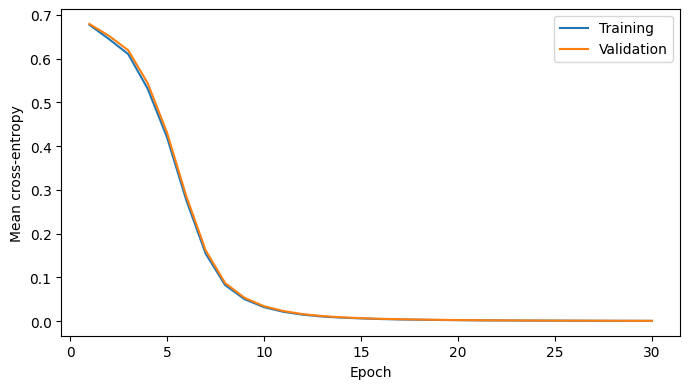

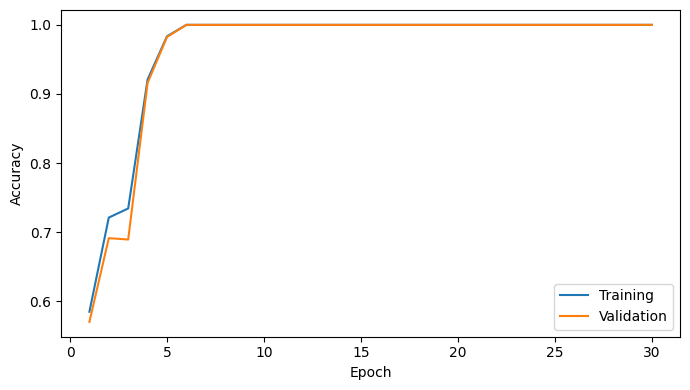

In [11]:
Path("results").mkdir(exist_ok=True)
epochs = [row["epoch"] for row in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [row["train_loss"] for row in history], label="Training")
plt.plot(epochs, [row["validation_loss"] for row in history], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Mean cross-entropy")
plt.legend()
plt.tight_layout()
plt.savefig("results/loss_curves.png", dpi=160)
plt.show()
plt.figure(figsize=(7, 4))
plt.plot(epochs, [row["train_accuracy"] for row in history], label="Training")
plt.plot(epochs, [row["validation_accuracy"] for row in history], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("results/accuracy_curves.png", dpi=160)
plt.show()

## 6. Seen versus unseen locations — no retraining
Use the **same selected checkpoint** on both test sets. Do not modify training
based on these results.

`evaluate(...)` returns loss, accuracy, positive recall, a 2×2 confusion matrix,
logits `(N,2)` and predictions `(N,)`, in the original split order. Metrics use
fractions. Positive recall is `TP/(TP+FN)`; confusion-matrix rows are true labels
and columns are predicted labels. Incomplete final batches are weighted by their
actual sample counts.

The two test sets contain separate sampled negatives with the same no-block
rule. They are **not paired translations of identical images**.

test_seen: accuracy=1.0000, positive recall=1.0000
Confusion matrix (true rows, predicted columns):
[[256   0]
 [  0 256]]


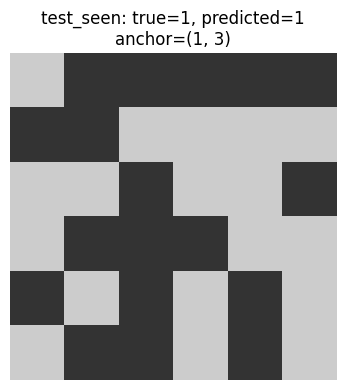

Layout ID: 44741017345 Logits: [-3.2380579  5.3769364]


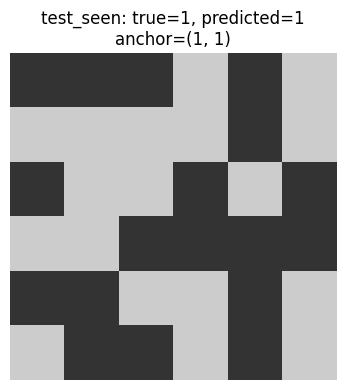

Layout ID: 44762491880 Logits: [-3.554319   5.4516797]
test_unseen: accuracy=1.0000, positive recall=1.0000
Confusion matrix (true rows, predicted columns):
[[256   0]
 [  0 256]]


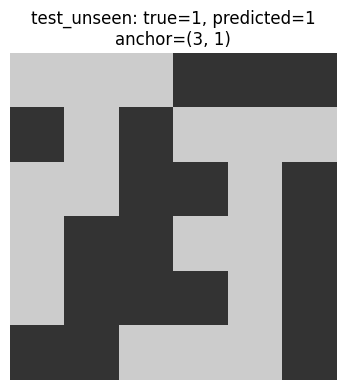

Layout ID: 30356618887 Logits: [-1.8547553  5.0851626]


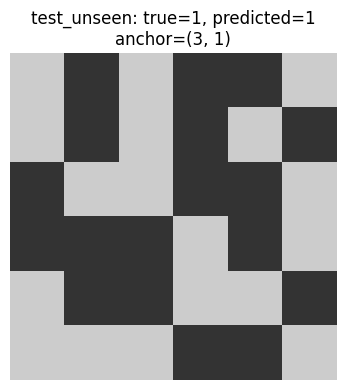

Layout ID: 42306004325 Logits: [-3.268149   6.4762278]


In [12]:
evaluations = {name: evaluate(model, data[name])
               for name in ("test_seen", "test_unseen")}
for name, result in evaluations.items():
    print(f"{name}: accuracy={result['accuracy']:.4f}, "
          f"positive recall={result['positive_recall']:.4f}")
    print("Confusion matrix (true rows, predicted columns):")
    print(result["confusion_matrix"])
    positive_ids = np.flatnonzero(data[name]["y"] == 1)[:2]
    for idx in positive_ids:
        plt.figure(figsize=(4, 4))
        plt.imshow(data[name]["x"][idx, 0], cmap="gray", vmin=0, vmax=1)
        pred = int(result["predictions"][idx])
        anchor = tuple(data[name]["anchor"][idx])
        plt.title(f"{name}: true=1, predicted={pred}\nanchor={anchor}")
        plt.axis("off")
        plt.tight_layout()
        plt.savefig(f"results/{name}_example_{idx}.png", dpi=160)
        plt.show()
        print("Layout ID:", int(data[name]["layout_id"][idx]),
              "Logits:", result["logits"][idx])

### Report discussion
Compare accuracy and positive recall across the two test sets. Use your own
curves, confusion matrices and examples. Discuss locality, weight sharing and
global max pooling. Explain what these measurements support for this trained
model, without turning a finite-sample result into a theorem of translation
invariance. Consider the zero padding, stride-2 pooling and changed sampled
backgrounds when qualifying your interpretation.

Two positive examples from each test set are shown above. Also discuss an error
when one is available. If no errors occur, say so rather than inventing one.

## 7. Save and submit
`save_run(...)` returns `None` and writes the checkpoint, history, metrics,
per-image predictions/IDs and configuration. Submit `cnn_layers.py`, `cnn.py`,
the executed notebook, report and `q2_results.zip`. Do not submit modified support code.

The saved checkpoint is an NPZ of parameter arrays, not a pickled model.

In [13]:
config = dict(data_seed=DATA_SEED, model_seed=MODEL_SEED, shuffle_seed=18,
              epochs=30, batch_size=64, learning_rate=0.003,
              seen_anchors=[[1,1],[1,3]], unseen_anchors=[[3,1],[3,3]])
save_run("results", model, history, summary, evaluations, data, config)
Path("results/dataset_audit.json").write_text(json.dumps(audit, indent=2))
Path("results/gradient_checks.json").write_text(json.dumps(gradient_results, indent=2))
import shutil
shutil.make_archive("q2_results", "zip", "results")
print("Submit:", Path("cnn_layers.py").resolve(), Path("cnn.py").resolve())
print("Results archive:", Path("q2_results.zip").resolve())

Submit: /store/home/mardenlim/IFT6135/Assignments_IFT6135/Assignment1/q2/q2_workspace/cnn_layers.py /store/home/mardenlim/IFT6135/Assignments_IFT6135/Assignment1/q2/q2_workspace/cnn.py
Results archive: /store/home/mardenlim/IFT6135/Assignments_IFT6135/Assignment1/q2/q2_workspace/q2_results.zip
